In [1]:
from pathlib import Path
import osmnx as ox
import geopandas as gpd
import rasterio
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
DATA_RAW = PROJECT_ROOT / "data" / "raw"
OUTPUTS = PROJECT_ROOT / "outputs"

G = ox.load_graphml(
    DATA_RAW / "sevilla_walk.graphml"
)

nodes, edges = ox.graph_to_gdfs(G)

print(nodes.crs)
print(edges.crs)

epsg:4326
epsg:4326


In [2]:
edges = edges.to_crs("EPSG:25830")
nodes = nodes.to_crs("EPSG:25830")

In [3]:
utci_path = (
    OUTPUTS
    / "solweig"
    / "summary"
    / "utci_max.tif"
)

with rasterio.open(utci_path) as src:
    print(src.crs)
    print(src.bounds)
    print(src.res)

EPSG:25830
BoundingBox(left=237173.53465099988, bottom=4141421.4097209056, right=239303.53465099988, top=4143551.4097209056)
(5.0, 5.0)


In [4]:
from shapely.geometry import box

with rasterio.open(utci_path) as src:
    raster_extent = box(*src.bounds)

edges_poc = edges[
    edges.intersects(raster_extent)
].copy()

print("Walking edges in thermal study area:", len(edges_poc))

Walking edges in thermal study area: 4612


In [5]:
edges_poc["midpoint"] = edges_poc.geometry.interpolate(
    0.5,
    normalized=True
)

In [6]:
coords = [
    (geom.x, geom.y)
    for geom in edges_poc["midpoint"]
]

In [7]:
with rasterio.open(utci_path) as src:
    sampled = [
        value[0]
        for value in src.sample(coords)
    ]

edges_poc["utci_max"] = sampled

In [8]:
edges_poc["utci_max"].describe()

count    4470.000000
mean       41.525200
std         0.515692
min        33.449070
25%        41.379044
50%        41.572536
75%        41.779427
max        42.742664
Name: utci_max, dtype: float64

In [9]:
edges_poc.loc[
    ~np.isfinite(edges_poc["utci_max"]),
    "utci_max"
] = np.nan

In [10]:
walking_speed_mps = 1.4

edges_poc["walk_time_s"] = (
    edges_poc["length"] / walking_speed_mps
)

In [11]:
edges_poc["heat_excess"] = np.maximum(
    edges_poc["utci_max"] - 32,
    0
)

In [12]:
lambda_heat = 0.05

edges_poc["thermal_cost_s"] = (
    edges_poc["walk_time_s"]
    *
    (
        1
        + lambda_heat
        * edges_poc["heat_excess"]
    )
)

In [13]:
lambda_heat = 0.05

edges_poc["thermal_cost_s"] = (
    edges_poc["walk_time_s"]
    *
    (
        1
        + lambda_heat
        * edges_poc["heat_excess"]
    )
)

In [14]:
edges_poc["cost_ratio"] = (
    edges_poc["thermal_cost_s"]
    /
    edges_poc["walk_time_s"]
)

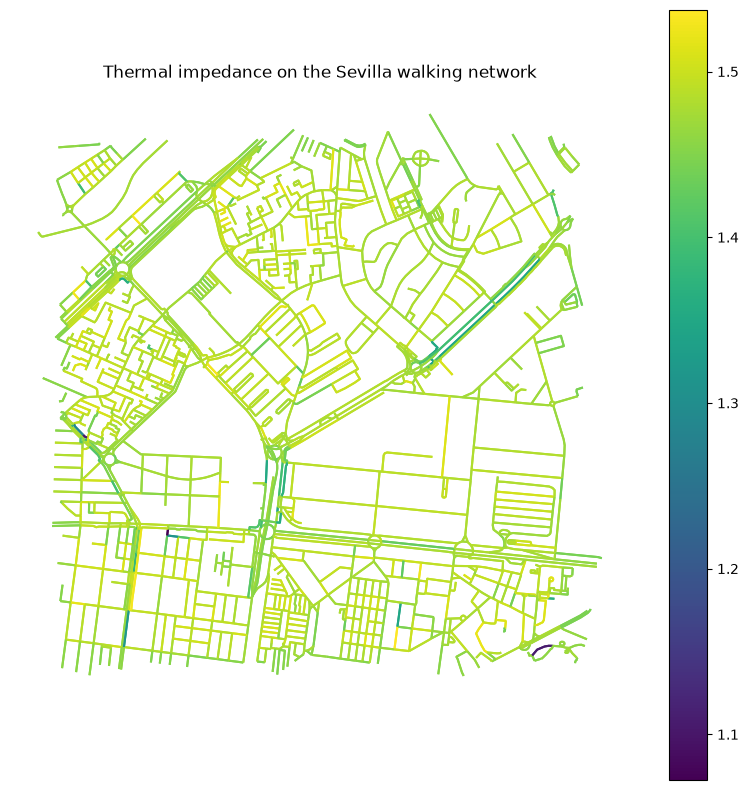

In [16]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10))

edges_poc.plot(
    ax=ax,
    column="cost_ratio",
    linewidth=1.5,
    legend=True
)

ax.set_title(
    "Thermal impedance on the Sevilla walking network"
)

ax.set_axis_off()
plt.show()